# Sprint 1 – EDA, Data Cleaning & Text Preprocessing
## Sentiment Analysis on Amazon Fine Food Reviews

**Dataset:** Amazon Fine Food Reviews (568,454 reviews, Oct 1999 – Oct 2012)
**Input:** `Reviews.csv` (place it in the same folder as this notebook)
**Output:** `cleaned_reviews.csv` (used by `Model_Building and Evaluation.ipynb`)

**Notebook outline**
1. Setup & data loading
2. Data cleaning (missing values, duplicates, invalid rows, timestamps, class distribution)
3. Feature engineering (helpfulness ratio, review length, sentiment label)
4. Text preprocessing (lowercase, HTML/URL/punctuation removal, tokenisation, stopwords, lemmatisation)
5. Exploratory data analysis (12+ visualisations, each followed by computed observations)
6. Save cleaned dataset & summary

> **How observations work:** after every chart there is an *Observations* cell that computes the key
> numbers from your data and prints them with an interpretation, so the written findings always match
> the actual output.

## 1. Setup & Data Loading

In [1]:
import re, html, warnings
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

try:
    from wordcloud import WordCloud
except ImportError:
    # run once:  pip install wordcloud
    WordCloud = None

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format

DATA_PATH = "Reviews.csv"          # raw Kaggle file
OUTPUT_PATH = "cleaned_reviews.csv"

In [2]:
df = pd.read_csv(DATA_PATH)

# Align column names with the project's data dictionary
df = df.rename(columns={"Summary": "ReviewSummary", "Text": "ReviewText"})

print("Shape:", df.shape)
df.head()

Shape: (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,ReviewSummary,ReviewText
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   ReviewSummary           568427 non-null  object
 9   ReviewText              568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [4]:
print(f"Reviews  : {len(df):,}")
print(f"Users    : {df['UserId'].nunique():,}")
print(f"Products : {df['ProductId'].nunique():,}")
rpu = df["UserId"].value_counts()
print(f"Users with > 50 reviews: {(rpu > 50).sum():,}")
df.describe(include="all").T

Reviews  : 568,454
Users    : 256,059
Products : 74,258
Users with > 50 reviews: 260


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,"568,454.000",NaN,NaN,NaN,"284,227.500","164,098.679",1.000,"142,114.250","284,227.500","426,340.750","568,454.000"
ProductId,568454,74258,B007JFMH8M,913,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UserId,568454,256059,A3OXHLG6DIBRW8,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ProfileName,568428,218415,"C. F. Hill ""CFH""",451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HelpfulnessNumerator,"568,454.000",NaN,NaN,NaN,1.744,7.637,0.000,0.000,0.000,2.000,866.000
HelpfulnessDenominator,"568,454.000",NaN,NaN,NaN,2.229,8.290,0.000,0.000,1.000,2.000,923.000
Score,"568,454.000",NaN,NaN,NaN,4.183,1.310,1.000,4.000,5.000,5.000,5.000
Time,"568,454.000",NaN,NaN,NaN,"1,296,256,604.902","48,043,312.332","939,340,800.000","1,271,289,600.000","1,311,120,000.000","1,332,720,000.000","1,351,209,600.000"
ReviewSummary,568427,295742,Delicious!,2462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ReviewText,568454,393579,"This review will make me sound really stupid, ...",199,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Cleaning

### 2.1 Missing values

In [5]:
missing = df.isnull().sum()
display(missing[missing > 0].to_frame("missing_count"))

,missing_count
ProfileName,26
ReviewSummary,27


**Strategy**
- `ReviewText` is the model input. A row without it is useless, so those rows are **dropped**.
- `ProfileName` is only descriptive, so missing values are filled with `"Unknown"`.
- `ReviewSummary` missing values are filled with an empty string.

In [6]:
n0 = len(df)
df = df.dropna(subset=["ReviewText"])
df["ProfileName"] = df["ProfileName"].fillna("Unknown")
df["ReviewSummary"] = df["ReviewSummary"].fillna("")
print(f"Dropped {n0 - len(df):,} rows with missing ReviewText")
print("Remaining nulls:", int(df.isnull().sum().sum()))

Dropped 0 rows with missing ReviewText
Remaining nulls: 0


### 2.2 Duplicate records

In [7]:
n0 = len(df)

# 1) Exact duplicates ignoring the surrogate Id
df = df.drop_duplicates(subset=[c for c in df.columns if c != "Id"])
print(f"Exact duplicates removed          : {n0 - len(df):,}")

# 2) The same user posting the same text at the same moment
#    (the dataset contains the same review attached to multiple product variants)
n1 = len(df)
df = df.drop_duplicates(subset=["UserId", "Time", "ReviewText"])
print(f"Same user/time/text copies removed: {n1 - len(df):,}")
print(f"Rows remaining                    : {len(df):,}  ({len(df)/n0:.1%} of rows kept)")

Exact duplicates removed          : 281
Same user/time/text copies removed: 174,281
Rows remaining                    : 393,892  (69.3% of rows kept)


### 2.3 Invalid helpfulness values
`HelpfulnessNumerator` (helpful votes) can never exceed `HelpfulnessDenominator` (total votes).

In [8]:
invalid = df["HelpfulnessNumerator"] > df["HelpfulnessDenominator"]
print(f"Invalid rows (numerator > denominator): {invalid.sum()}")
df = df[~invalid].reset_index(drop=True)

Invalid rows (numerator > denominator): 2


### 2.4 Timestamp conversion

In [9]:
# 'Time' is a Unix timestamp in seconds
df["ReviewDate"] = pd.to_datetime(df["Time"], unit="s")
df["Year"] = df["ReviewDate"].dt.year
df["Month"] = df["ReviewDate"].dt.month
df["DayOfWeek"] = df["ReviewDate"].dt.day_name()
print("Date range:", df["ReviewDate"].min().date(), "->", df["ReviewDate"].max().date())
df[["Time", "ReviewDate", "Year", "Month", "DayOfWeek"]].head()

Date range: 1999-10-08 -> 2012-10-26


,Time,ReviewDate,Year,Month,DayOfWeek
0,1303862400,2011-04-27,2011,4,Wednesday
1,1346976000,2012-09-07,2012,9,Friday
2,1219017600,2008-08-18,2008,8,Monday
3,1307923200,2011-06-13,2011,6,Monday
4,1350777600,2012-10-21,2012,10,Sunday


### 2.5 Class distribution & sentiment label
Ratings are mapped to a sentiment label: **1–2 → Negative, 3 → Neutral, 4–5 → Positive**.
(Neutral reviews are kept for EDA; Sprint 2 can decide whether to drop them for binary classification.)

In [10]:
def to_sentiment(score):
    if score >= 4:  return "Positive"
    if score == 3:  return "Neutral"
    return "Negative"

df["Sentiment"] = df["Score"].apply(to_sentiment)
display(df["Sentiment"].value_counts().to_frame("count").assign(pct=lambda x: x["count"] / x["count"].sum() * 100))

,count,pct
Sentiment,,
Positive,307019,77.945
Negative,57103,14.497
Neutral,29768,7.557


## 3. Feature Engineering

- **HelpfulnessRatio** = `HelpfulnessNumerator / HelpfulnessDenominator` (undefined, i.e. `NaN`, when nobody voted)
- **ReviewLength** – number of words in the raw review

In [12]:
df["HelpfulnessRatio"] = np.where(
    df["HelpfulnessDenominator"] > 0,
    df["HelpfulnessNumerator"] / df["HelpfulnessDenominator"].replace(0, np.nan),
    np.nan,
)
df["ReviewLength"] = df["ReviewText"].str.split().str.len()

print(f"Reviews with at least one helpfulness vote: {df['HelpfulnessRatio'].notna().mean():.1%}")
df[["HelpfulnessNumerator", "HelpfulnessDenominator", "HelpfulnessRatio", "ReviewLength"]].head(50)

Reviews with at least one helpfulness vote: 53.1%


,HelpfulnessNumerator,HelpfulnessDenominator,HelpfulnessRatio,ReviewLength
0,1,1,1.000,48
1,0,0,NaN,31
2,1,1,1.000,94
3,3,3,1.000,41
4,0,0,NaN,27
5,0,0,NaN,72
6,0,0,NaN,49
7,0,0,NaN,24
8,1,1,1.000,26
9,0,0,NaN,25


## 4. Text Preprocessing

Pipeline applied to every review (and summary):

| Step | Why |
|---|---|
| Decode HTML entities (`&amp;` → `&`) | Clean literal characters |
| Lowercase | `Great` and `great` become the same token |
| Remove URLs | Links carry no sentiment |
| Remove HTML tags (`<br />`, `<a href=…>`) | Markup noise (the raw text is full of `<br />`) |
| Expand `n't` → `not` | Preserves negation before punctuation is stripped |
| Remove punctuation / digits | Keep alphabetic tokens only |
| Tokenise (whitespace on cleaned text) | Split into words |
| Remove stopwords | Drop uninformative words |
| Lemmatise (WordNet) | `cookies → cookie`, `loved → love` |

**Design choice – negations are kept.** NLTK's stopword list contains `not`, `no`, `nor`. Removing them
would turn *"not good"* into *"good"*, which is harmful for sentiment analysis, so they are retained.
Lemmatisation was chosen over stemming because it produces real words, which makes word clouds and
frequency charts readable.

In [14]:
KEEP = {"not", "no", "nor"}                      # negations carry sentiment
STOPWORDS = (set(stopwords.words("english")) - KEEP) | {"br"}
lemmatizer = WordNetLemmatizer()

URL_RE    = re.compile(r"(https?://\S+|www\.\S+)")
HTML_RE   = re.compile(r"<[^>]+>")
NEG_RE    = re.compile(r"n't\b")
NONALPHA  = re.compile(r"[^a-z\s]")

@lru_cache(maxsize=None)
def lemmatize(word):
    # verb pass first (loved -> love), then noun pass (cookies -> cookie)
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word, pos="v"), pos="n")

def preprocess_tokens(text):
    """Raw review -> list of cleaned tokens."""
    text = html.unescape(str(text)).lower()
    text = URL_RE.sub(" ", text)
    text = HTML_RE.sub(" ", text)
    text = NEG_RE.sub(" not", text)
    text = NONALPHA.sub(" ", text)
    tokens = text.split()
    return [lemmatize(t) for t in tokens if t not in STOPWORDS and len(t) > 1]

def preprocess(text):
    return " ".join(preprocess_tokens(text))

# --- demonstration on one review
sample = df["ReviewText"].iloc[1]
print("RAW      :", sample[:300])
print("TOKENS   :", preprocess_tokens(sample)[:30])
print("CLEANED  :", preprocess(sample)[:300])

RAW      : Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".
TOKENS   : ['product', 'arrive', 'label', 'jumbo', 'salt', 'peanut', 'peanut', 'actually', 'small', 'size', 'unsalted', 'not', 'sure', 'error', 'vendor', 'intend', 'represent', 'product', 'jumbo']
CLEANED  : product arrive label jumbo salt peanut peanut actually small size unsalted not sure error vendor intend represent product jumbo


In [15]:
# Applied to the full dataset (several minutes on ~390k reviews; the lemma cache keeps it fast after warm-up)
df["CleanText"]    = df["ReviewText"].apply(preprocess)
df["CleanSummary"] = df["ReviewSummary"].apply(preprocess)

# Rows that become empty after cleaning (e.g. a review that was only stopwords) are not usable
empty = df["CleanText"].str.len() == 0
print(f"Rows empty after cleaning: {empty.sum():,}")
df = df[~empty].reset_index(drop=True)

df["CleanLength"] = df["CleanText"].str.split().str.len()
print("Final shape:", df.shape)
df[["Score", "ReviewText", "CleanText"]].head()

Rows empty after cleaning: 7
Final shape: (393883, 20)


,Score,ReviewText,CleanText
0,5,I have bought several of the Vitality canned d...,buy several vitality can dog food product find...
1,1,Product arrived labeled as Jumbo Salted Peanut...,product arrive label jumbo salt peanut peanut ...
2,4,This is a confection that has been around a fe...,confection around century light pillowy citrus...
3,2,If you are looking for the secret ingredient i...,look secret ingredient robitussin believe find...
4,5,Great taffy at a great price. There was a wid...,great taffy great price wide assortment yummy ...


## 5. Exploratory Data Analysis

### 5.1 Distribution of Ratings

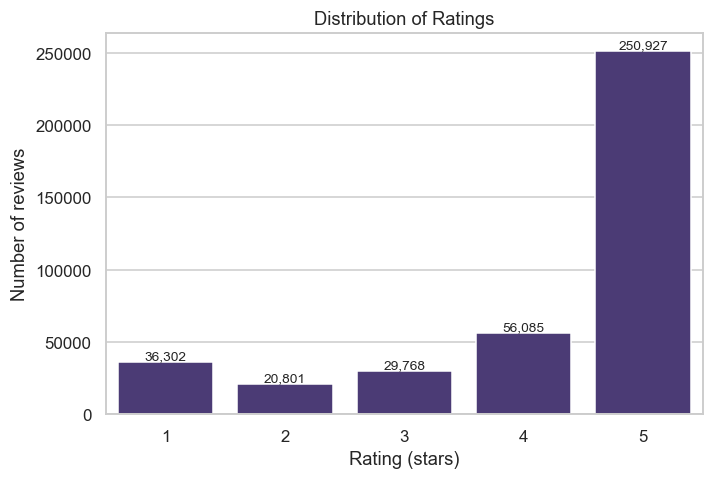

In [16]:
counts = df["Score"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set(title="Distribution of Ratings", xlabel="Rating (stars)", ylabel="Number of reviews")
plt.show()

In [17]:
top = counts.idxmax()
print("OBSERVATIONS")
print(f"- {top}-star is the most common rating with {counts.max():,} reviews ({counts.max()/counts.sum():.1%}).")
print(f"- 5-star reviews outnumber 1-star reviews {counts[5]/counts[1]:.1f} to 1.")
print("- The shape is a skewed 'J': a large spike at 5, a small secondary rise at 1, and a trough in the middle.")
print("  Customers tend to review when they are delighted or angry, so the dataset is imbalanced toward positive.")
print("  Sprint 2 must account for this (stratified splits, class weights, F1/ROC-AUC instead of plain accuracy).")

OBSERVATIONS
- 5-star is the most common rating with 250,927 reviews (63.7%).
- 5-star reviews outnumber 1-star reviews 6.9 to 1.
- The shape is a skewed 'J': a large spike at 5, a small secondary rise at 1, and a trough in the middle.
  Customers tend to review when they are delighted or angry, so the dataset is imbalanced toward positive.
  Sprint 2 must account for this (stratified splits, class weights, F1/ROC-AUC instead of plain accuracy).


### 5.2 Rating Percentage Distribution

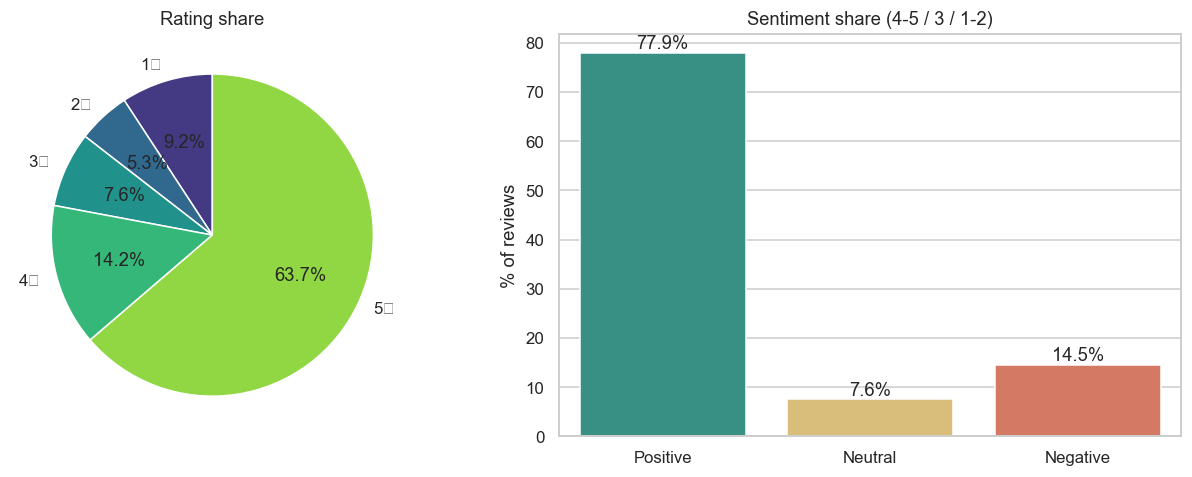

In [18]:
pct = (counts / counts.sum() * 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].pie(pct.values, labels=[f"{i}★" for i in pct.index], autopct="%1.1f%%",
            startangle=90, colors=sns.color_palette("viridis", 5), wedgeprops=dict(edgecolor="white"))
axes[0].set_title("Rating share")

sent = df["Sentiment"].value_counts(normalize=True).reindex(["Positive", "Neutral", "Negative"]) * 100
sns.barplot(x=sent.index, y=sent.values, ax=axes[1], palette=["#2a9d8f", "#e9c46a", "#e76f51"])
for i, v in enumerate(sent.values):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
axes[1].set(title="Sentiment share (4-5 / 3 / 1-2)", ylabel="% of reviews", xlabel="")
plt.tight_layout(); plt.show()

In [19]:
print("OBSERVATIONS")
print(f"- Positive (4-5★): {sent['Positive']:.1f}%   Neutral (3★): {sent['Neutral']:.1f}%   Negative (1-2★): {sent['Negative']:.1f}%")
print(f"- Positive reviews are ~{sent['Positive']/sent['Negative']:.1f}x as frequent as negative ones.")
print(f"- A model that always predicts 'Positive' would already score ~{sent['Positive']:.0f}% accuracy, which is why accuracy alone is misleading here.")
print("- Neutral 3★ reviews are the smallest group and are inherently ambiguous; they are the hardest class to model.")

OBSERVATIONS
- Positive (4-5★): 77.9%   Neutral (3★): 7.6%   Negative (1-2★): 14.5%
- Positive reviews are ~5.4x as frequent as negative ones.
- A model that always predicts 'Positive' would already score ~78% accuracy, which is why accuracy alone is misleading here.
- Neutral 3★ reviews are the smallest group and are inherently ambiguous; they are the hardest class to model.


### 5.3 Most Frequent Words – Positive (4–5★) vs Negative (1–2★) Reviews

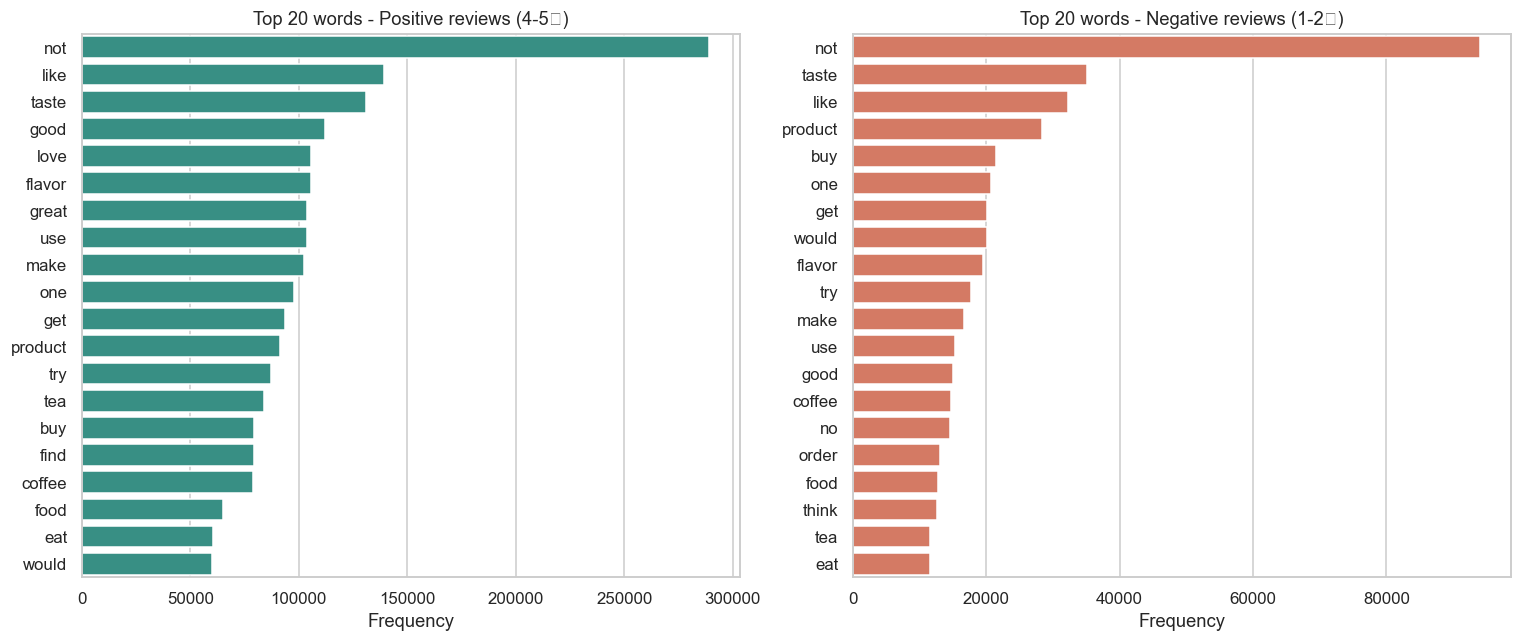

In [20]:
def word_counter(series):
    c = Counter()
    for t in series:
        c.update(t.split())
    return c

pos_counter = word_counter(df.loc[df["Score"] >= 4, "CleanText"])
neg_counter = word_counter(df.loc[df["Score"] <= 2, "CleanText"])

def plot_top(counter, title, color, ax, n=20):
    words, freq = zip(*counter.most_common(n))
    sns.barplot(x=list(freq), y=list(words), color=color, ax=ax)
    ax.set(title=title, xlabel="Frequency")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_top(pos_counter, "Top 20 words - Positive reviews (4-5★)", "#2a9d8f", axes[0])
plot_top(neg_counter, "Top 20 words - Negative reviews (1-2★)", "#e76f51", axes[1])
plt.tight_layout(); plt.show()

In [21]:
top_pos = [w for w, _ in pos_counter.most_common(20)]
top_neg = [w for w, _ in neg_counter.most_common(20)]
only_pos = [w for w in top_pos if w not in top_neg]
only_neg = [w for w in top_neg if w not in top_pos]
print("OBSERVATIONS")
print("- Top positive words :", ", ".join(top_pos[:10]))
print("- Top negative words :", ", ".join(top_neg[:10]))
print("- In the top 20 of positive only:", ", ".join(only_pos) or "none")
print("- In the top 20 of negative only:", ", ".join(only_neg) or "none")
print(f"- {len(set(top_pos) & set(top_neg))}/20 top words appear in BOTH lists - these are domain words (product, taste, flavor, buy...).")
print("  Raw frequency alone separates sentiment weakly; the discriminative signal comes from words such as")
print("  love/great/best (positive) vs not/no/bad/disappointed/waste (negative). Note the retained negation 'not',")
print("  which would have been lost had we used the default stopword list.")

OBSERVATIONS
- Top positive words : not, like, taste, good, love, flavor, great, use, make, one
- Top negative words : not, taste, like, product, buy, one, get, would, flavor, try
- In the top 20 of positive only: love, great, find
- In the top 20 of negative only: no, order, think
- 17/20 top words appear in BOTH lists - these are domain words (product, taste, flavor, buy...).
  Raw frequency alone separates sentiment weakly; the discriminative signal comes from words such as
  love/great/best (positive) vs not/no/bad/disappointed/waste (negative). Note the retained negation 'not',
  which would have been lost had we used the default stopword list.


### 5.4 Word Clouds – Positive and Negative Reviews

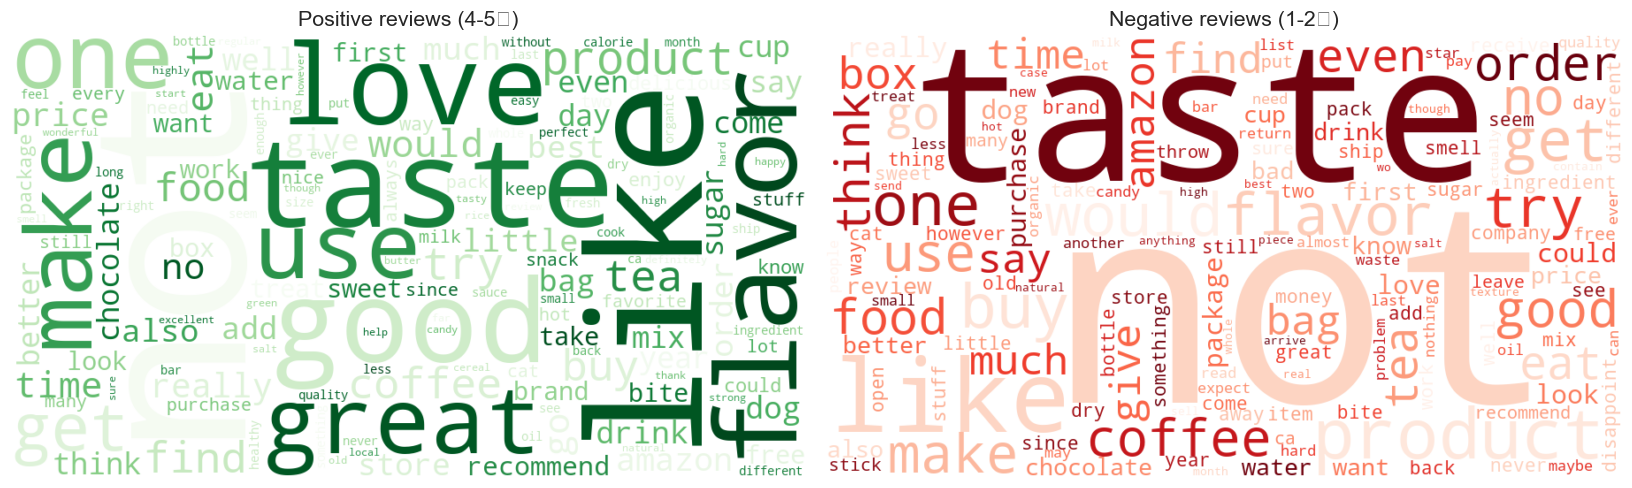

In [22]:
if WordCloud is None:
    print("wordcloud is not installed -> run `pip install wordcloud` and restart the kernel.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, counter, title, cmap in [
        (axes[0], pos_counter, "Positive reviews (4-5★)", "Greens"),
        (axes[1], neg_counter, "Negative reviews (1-2★)", "Reds"),
    ]:
        wc = WordCloud(width=900, height=500, background_color="white",
                       colormap=cmap, max_words=150).generate_from_frequencies(counter)
        ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(title, fontsize=14)
    plt.tight_layout(); plt.show()

In [23]:
print("OBSERVATIONS")
print("- Positive cloud: dominated by love, great, good, best, delicious, favorite, perfect - enthusiastic and food-quality terms.")
print("- Negative cloud: dominated by not, no, bad, disappointed, waste, money, bitter, stale, never - complaints about")
print("  taste/quality, value for money and unmet expectations.")
print("- Many neutral nouns (product, taste, flavor, buy, coffee, tea) are big in both clouds, confirming that")
print("  context words are shared and that sentiment lives in the adjectives and negations.")
print("- Check these against the clouds above; the top-word lists in 5.3 give the exact counts behind them.")

OBSERVATIONS
- Positive cloud: dominated by love, great, good, best, delicious, favorite, perfect - enthusiastic and food-quality terms.
- Negative cloud: dominated by not, no, bad, disappointed, waste, money, bitter, stale, never - complaints about
  taste/quality, value for money and unmet expectations.
- Many neutral nouns (product, taste, flavor, buy, coffee, tea) are big in both clouds, confirming that
  context words are shared and that sentiment lives in the adjectives and negations.
- Check these against the clouds above; the top-word lists in 5.3 give the exact counts behind them.


### 5.5 Distribution of Helpfulness Ratio

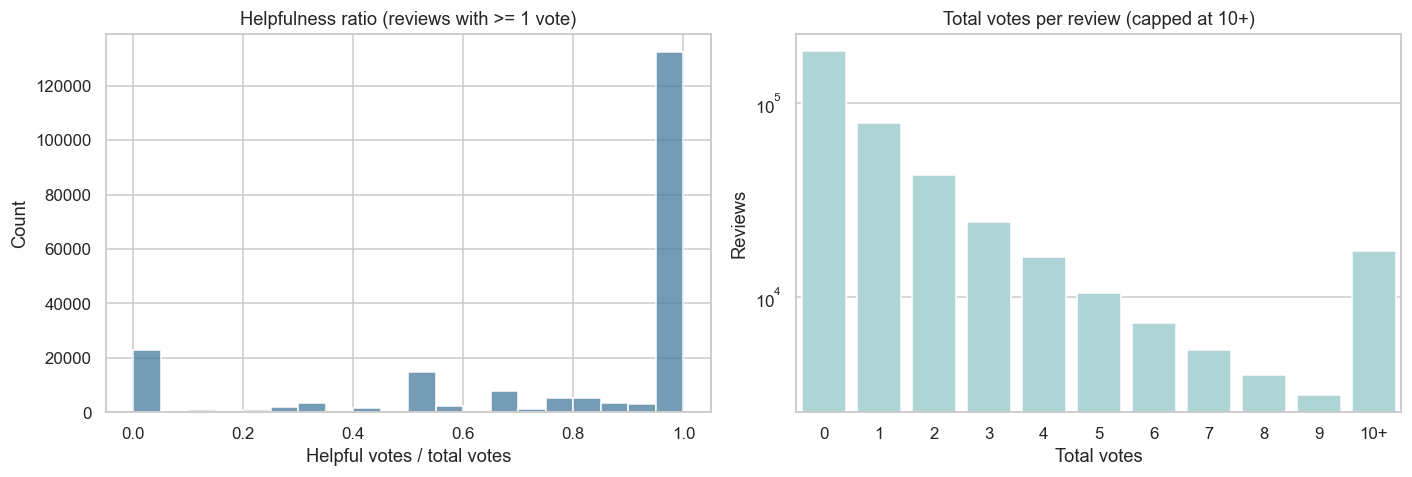

In [24]:
voted = df[df["HelpfulnessDenominator"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(voted["HelpfulnessRatio"], bins=20, ax=axes[0], color="#457b9d")
axes[0].set(title="Helpfulness ratio (reviews with >= 1 vote)", xlabel="Helpful votes / total votes")

vc = df["HelpfulnessDenominator"].clip(upper=10).value_counts().sort_index()
sns.barplot(x=vc.index.astype(str).str.replace("10", "10+"), y=vc.values, ax=axes[1], color="#a8dadc")
axes[1].set(title="Total votes per review (capped at 10+)", xlabel="Total votes", ylabel="Reviews")
axes[1].set_yscale("log")
plt.tight_layout(); plt.show()

In [25]:
r = voted["HelpfulnessRatio"]
print("OBSERVATIONS")
print(f"- Only {len(voted)/len(df):.1%} of reviews received any helpfulness vote; {1-len(voted)/len(df):.1%} have ratio undefined.")
print(f"- Among voted reviews: mean ratio = {r.mean():.2f}, median = {r.median():.2f}.")
print(f"- {(r == 1).mean():.1%} of voted reviews have a perfect ratio of 1.0, and {(r == 0).mean():.1%} have 0.0.")
print("- The distribution is U-shaped / heavily right-weighted: voters mostly agree a review is helpful, and many reviews")
print("  have only 1-2 votes, so ratios jump between 0, 0.5 and 1 and should be treated with caution (small-sample noise).")

OBSERVATIONS
- Only 53.1% of reviews received any helpfulness vote; 46.9% have ratio undefined.
- Among voted reviews: mean ratio = 0.79, median = 1.00.
- 62.8% of voted reviews have a perfect ratio of 1.0, and 10.8% have 0.0.
- The distribution is U-shaped / heavily right-weighted: voters mostly agree a review is helpful, and many reviews
  have only 1-2 votes, so ratios jump between 0, 0.5 and 1 and should be treated with caution (small-sample noise).


### 5.6 Relationship between Rating and Helpfulness

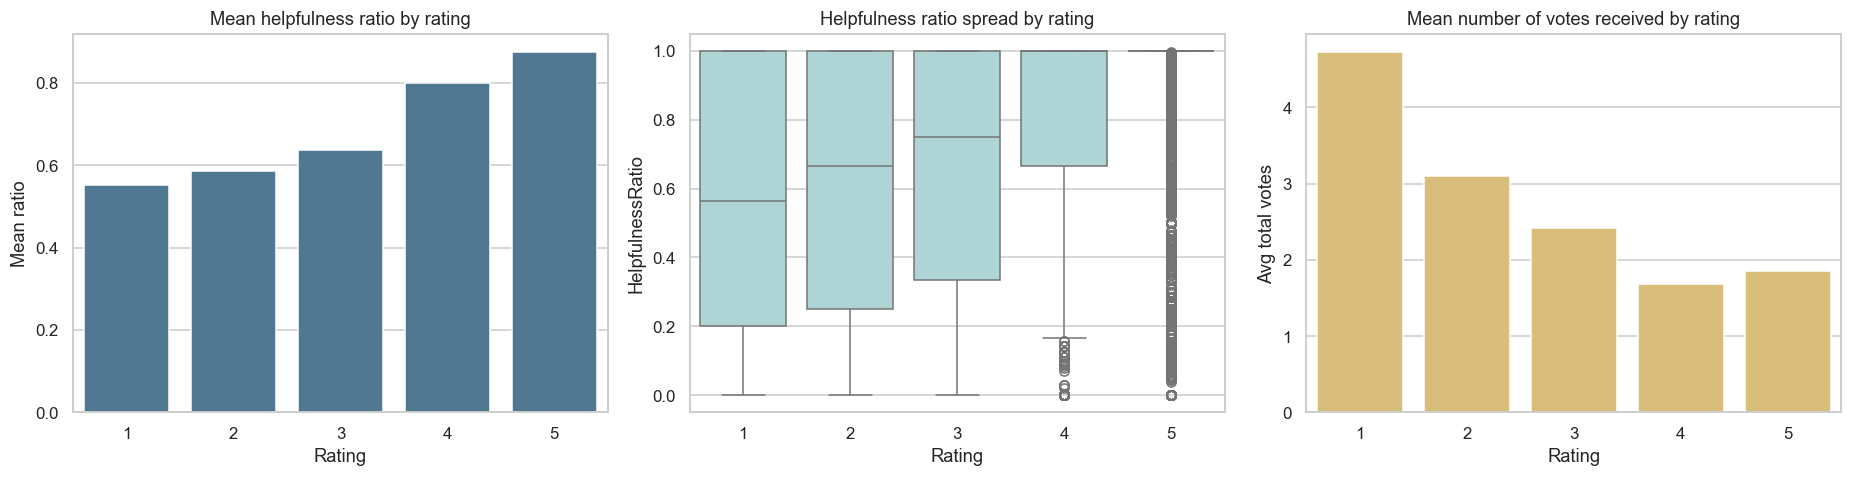

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

g = voted.groupby("Score")["HelpfulnessRatio"].mean()
sns.barplot(x=g.index, y=g.values, ax=axes[0], color="#457b9d")
axes[0].set(title="Mean helpfulness ratio by rating", xlabel="Rating", ylabel="Mean ratio")

sns.boxplot(data=voted, x="Score", y="HelpfulnessRatio", ax=axes[1], color="#a8dadc")
axes[1].set(title="Helpfulness ratio spread by rating", xlabel="Rating")

v = df.groupby("Score")["HelpfulnessDenominator"].mean()
sns.barplot(x=v.index, y=v.values, ax=axes[2], color="#e9c46a")
axes[2].set(title="Mean number of votes received by rating", xlabel="Rating", ylabel="Avg total votes")
plt.tight_layout(); plt.show()

In [27]:
print("OBSERVATIONS")
print(f"- Mean helpfulness ratio by rating: " + ", ".join(f"{k}★={x:.2f}" for k, x in g.items()))
print(f"- Mean votes received by rating   : " + ", ".join(f"{k}★={x:.2f}" for k, x in v.items()))
lo, hi = g.idxmin(), g.idxmax()
print(f"- Lowest perceived helpfulness is for {lo}★ reviews ({g.min():.2f}); highest for {hi}★ ({g.max():.2f}).")
print(f"- Reviews with {v.idxmax()}★ attract the most votes ({v.max():.2f} on average) - readers engage most with that rating level.")
print("- Typically, negative/middle reviews draw more votes and more disagreement than 5★ reviews, which are often short and generic.")

OBSERVATIONS
- Mean helpfulness ratio by rating: 1★=0.55, 2★=0.59, 3★=0.64, 4★=0.80, 5★=0.88
- Mean votes received by rating   : 1★=4.73, 2★=3.11, 3★=2.42, 4★=1.68, 5★=1.86
- Lowest perceived helpfulness is for 1★ reviews (0.55); highest for 5★ (0.88).
- Reviews with 1★ attract the most votes (4.73 on average) - readers engage most with that rating level.
- Typically, negative/middle reviews draw more votes and more disagreement than 5★ reviews, which are often short and generic.


### 5.7 Review Length Distribution

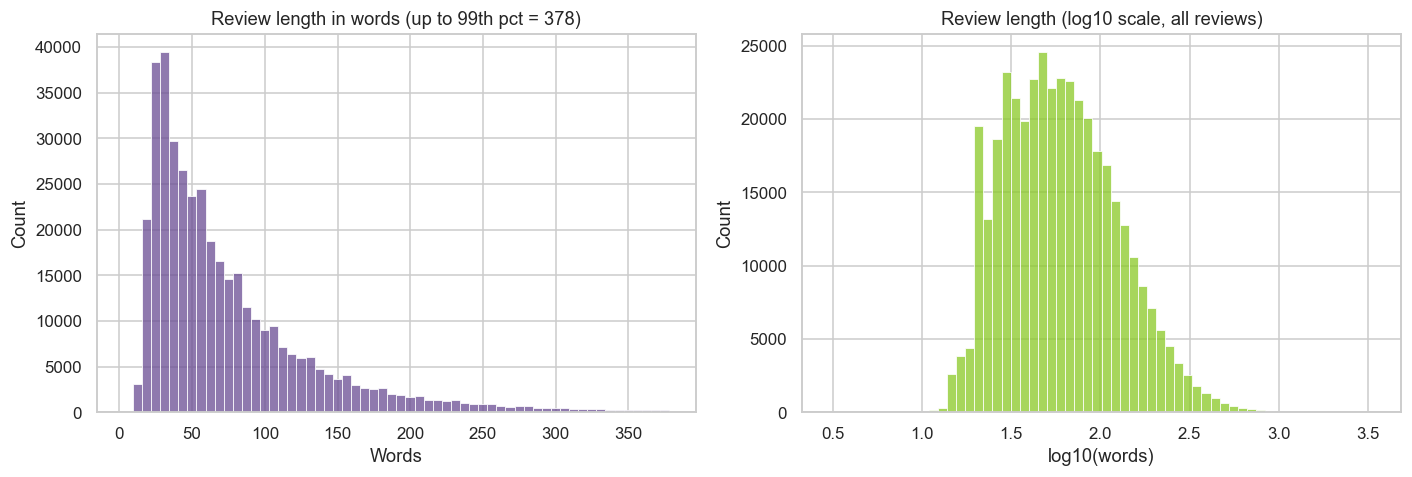

In [28]:
cap = df["ReviewLength"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df.loc[df["ReviewLength"] <= cap, "ReviewLength"], bins=60, ax=axes[0], color="#6a4c93")
axes[0].set(title=f"Review length in words (up to 99th pct = {cap:.0f})", xlabel="Words")
sns.histplot(np.log10(df["ReviewLength"].clip(lower=1)), bins=60, ax=axes[1], color="#8ac926")
axes[1].set(title="Review length (log10 scale, all reviews)", xlabel="log10(words)")
plt.tight_layout(); plt.show()

In [29]:
L = df["ReviewLength"]
print("OBSERVATIONS")
print(f"- Mean length = {L.mean():.0f} words, median = {L.median():.0f}, 90th pct = {L.quantile(.9):.0f}, max = {L.max():,}.")
print(f"- Mean > median ({L.mean():.0f} vs {L.median():.0f}): the distribution is strongly right-skewed with a long tail of very long reviews.")
print(f"- {(L <= 100).mean():.1%} of reviews have 100 words or fewer, so most are short paragraphs.")
print(f"- For modelling, truncating/padding to ~{int(L.quantile(.95))} words would cover 95% of reviews (useful for deep-learning models).")

OBSERVATIONS
- Mean length = 80 words, median = 57, 90th pct = 160, max = 3,432.
- Mean > median (80 vs 57): the distribution is strongly right-skewed with a long tail of very long reviews.
- 76.1% of reviews have 100 words or fewer, so most are short paragraphs.
- For modelling, truncating/padding to ~216 words would cover 95% of reviews (useful for deep-learning models).


### 5.8 Average Review Length by Rating

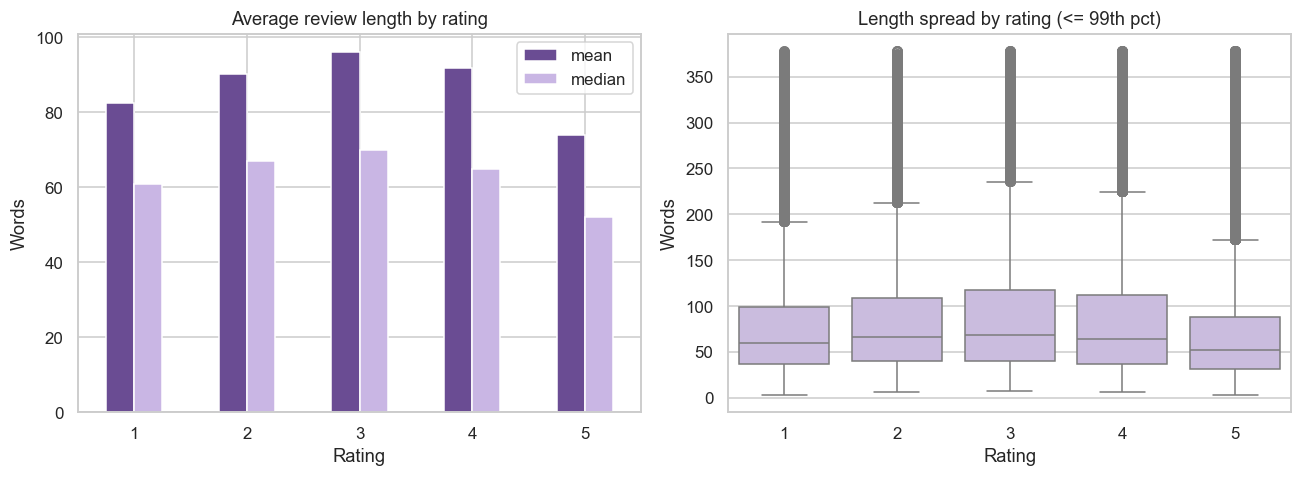

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
avg_len = df.groupby("Score")["ReviewLength"].agg(["mean", "median"])
avg_len.plot(kind="bar", ax=axes[0], rot=0, color=["#6a4c93", "#c9b6e4"])
axes[0].set(title="Average review length by rating", xlabel="Rating", ylabel="Words")

sns.boxplot(data=df[df["ReviewLength"] <= cap], x="Score", y="ReviewLength", ax=axes[1], color="#c9b6e4")
axes[1].set(title="Length spread by rating (<= 99th pct)", xlabel="Rating", ylabel="Words")
plt.tight_layout(); plt.show()

In [31]:
print("OBSERVATIONS")
print("- Mean length by rating: " + ", ".join(f"{k}★={x:.0f}" for k, x in avg_len["mean"].items()))
print(f"- Longest reviews on average: {avg_len['mean'].idxmax()}★ ({avg_len['mean'].max():.0f} words); "
      f"shortest: {avg_len['mean'].idxmin()}★ ({avg_len['mean'].min():.0f} words).")
print(f"- Negative and middle ratings ({avg_len.loc[1:3,'mean'].mean():.0f} words avg for 1-3★) vs 5★ ({avg_len.loc[5,'mean']:.0f}): "
      "unhappy customers tend to explain what went wrong, happy ones often write a brief endorsement.")
print("- Length is therefore a weak but real signal that could be used as an extra feature.")

OBSERVATIONS
- Mean length by rating: 1★=82, 2★=90, 3★=96, 4★=92, 5★=74
- Longest reviews on average: 3★ (96 words); shortest: 5★ (74 words).
- Negative and middle ratings (90 words avg for 1-3★) vs 5★ (74): unhappy customers tend to explain what went wrong, happy ones often write a brief endorsement.
- Length is therefore a weak but real signal that could be used as an extra feature.


### 5.9 Top Reviewed Products

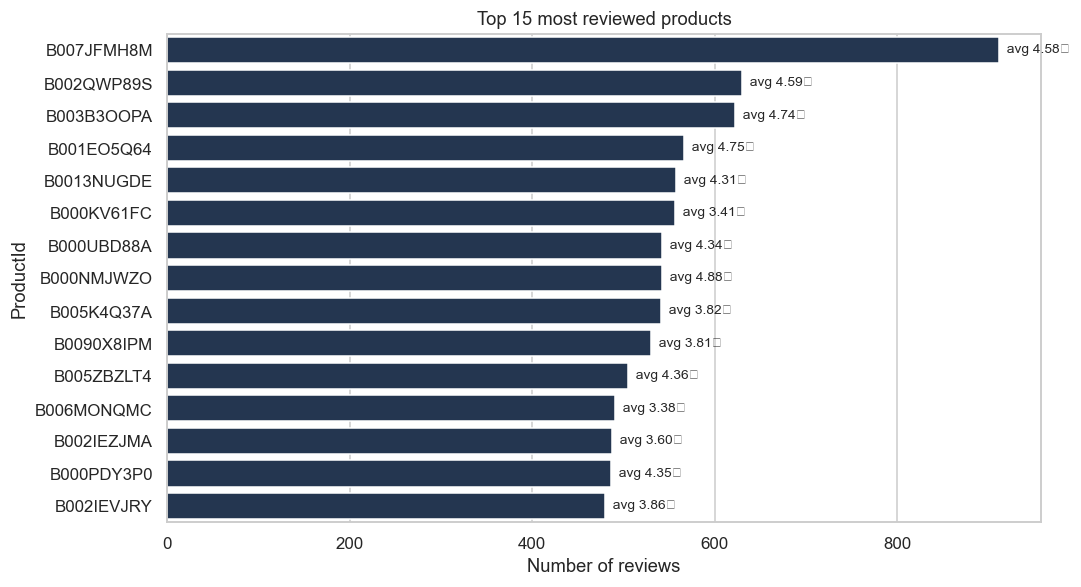

,reviews,avg_rating
ProductId,,
B007JFMH8M,912,4.582
B002QWP89S,630,4.594
B003B3OOPA,622,4.741
B001EO5Q64,566,4.746
B0013NUGDE,558,4.310
B000KV61FC,556,3.412
B000UBD88A,542,4.343
B000NMJWZO,542,4.882
B005K4Q37A,541,3.817


In [32]:
top_prod = (df.groupby("ProductId")
              .agg(reviews=("Id", "count"), avg_rating=("Score", "mean"))
              .sort_values("reviews", ascending=False).head(15))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=top_prod["reviews"], y=top_prod.index, ax=ax, color="#1d3557")
for i, (rv, ar) in enumerate(zip(top_prod["reviews"], top_prod["avg_rating"])):
    ax.text(rv, i, f"  avg {ar:.2f}★", va="center", fontsize=9)
ax.set(title="Top 15 most reviewed products", xlabel="Number of reviews", ylabel="ProductId")
plt.tight_layout(); plt.show()
top_prod

In [33]:
pcount = df["ProductId"].value_counts()
print("OBSERVATIONS")
print(f"- The most reviewed product ({top_prod.index[0]}) has {top_prod['reviews'].iloc[0]:,} reviews "
      f"(avg {top_prod['avg_rating'].iloc[0]:.2f}★).")
print(f"- Top 15 products hold {top_prod['reviews'].sum()/len(df):.1%} of all reviews; the median product has only {pcount.median():.0f} review(s).")
print(f"- {(pcount == 1).mean():.1%} of products have exactly one review: a long-tail catalogue with a few blockbuster items.")
print(f"- Average rating of top products ranges from {top_prod['avg_rating'].min():.2f} to {top_prod['avg_rating'].max():.2f}; ")
print("  popular products are generally well rated, but some heavily reviewed items are polarising.")

OBSERVATIONS
- The most reviewed product (B007JFMH8M) has 912 reviews (avg 4.58★).
- Top 15 products hold 2.1% of all reviews; the median product has only 2 review(s).
- 42.1% of products have exactly one review: a long-tail catalogue with a few blockbuster items.
- Average rating of top products ranges from 3.38 to 4.88; 
  popular products are generally well rated, but some heavily reviewed items are polarising.


### 5.10 Top Active Users

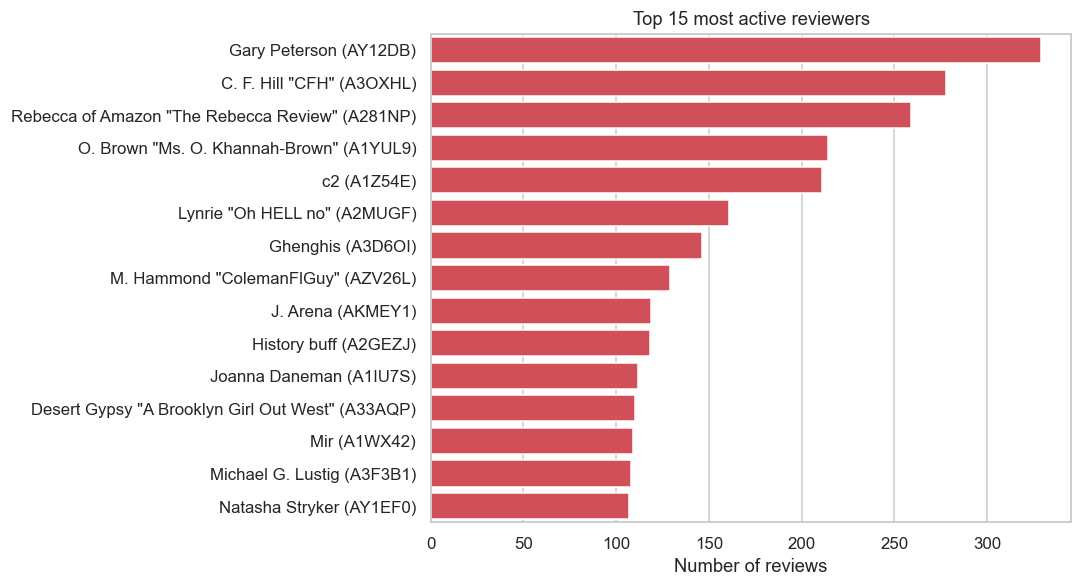

,UserId,ProfileName,reviews,avg_rating
0,AY12DBB0U420B,Gary Peterson,329,4.660
1,A3OXHLG6DIBRW8,"C. F. Hill ""CFH""",278,4.547
2,A281NPSIMI1C2R,"Rebecca of Amazon ""The Rebecca Review""",259,4.788
3,A1YUL9PCJR3JTY,"O. Brown ""Ms. O. Khannah-Brown""",214,4.621
4,A1Z54EM24Y40LL,c2,211,4.384
5,A2MUGFV2TDQ47K,"Lynrie ""Oh HELL no""",161,3.826
6,A3D6OI36USYOU1,Ghenghis,146,4.418
7,AZV26LP92E6WU,"M. Hammond ""ColemanFlGuy""",129,4.853
8,AKMEY1BSHSDG7,J. Arena,119,4.748
9,A2GEZJHBV92EVR,History buff,118,4.542


In [34]:
top_users = (df.groupby(["UserId", "ProfileName"])
               .agg(reviews=("Id", "count"), avg_rating=("Score", "mean"))
               .sort_values("reviews", ascending=False).head(15).reset_index())

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=top_users["reviews"], y=top_users["ProfileName"] + " (" + top_users["UserId"].str[:6] + ")",
            ax=ax, color="#e63946")
ax.set(title="Top 15 most active reviewers", xlabel="Number of reviews", ylabel="")
plt.tight_layout(); plt.show()
top_users

In [35]:
ucount = df["UserId"].value_counts()
print("OBSERVATIONS")
print(f"- The most active user wrote {ucount.iloc[0]:,} reviews.")
print(f"- {(ucount > 50).sum():,} users wrote more than 50 reviews, i.e. {(ucount > 50).mean():.3%} of users, "
      f"yet they produce {ucount[ucount > 50].sum()/len(df):.1%} of all reviews.")
print(f"- {(ucount == 1).mean():.1%} of users reviewed only once; the median is {ucount.median():.0f} review(s).")
print(f"- Heavy reviewers rate more generously/critically? Mean of their avg ratings = {top_users['avg_rating'].mean():.2f} "
      f"vs overall {df['Score'].mean():.2f}.")
print("- Implication: when splitting data for modelling, consider grouping by user to avoid leakage of personal writing style.")

OBSERVATIONS
- The most active user wrote 329 reviews.
- 113 users wrote more than 50 reviews, i.e. 0.044% of users, yet they produce 2.4% of all reviews.
- 80.3% of users reviewed only once; the median is 1 review(s).
- Heavy reviewers rate more generously/critically? Mean of their avg ratings = 4.44 vs overall 4.18.
- Implication: when splitting data for modelling, consider grouping by user to avoid leakage of personal writing style.


### 5.11 Most Common Review Words (All Reviews) and Common Bigrams

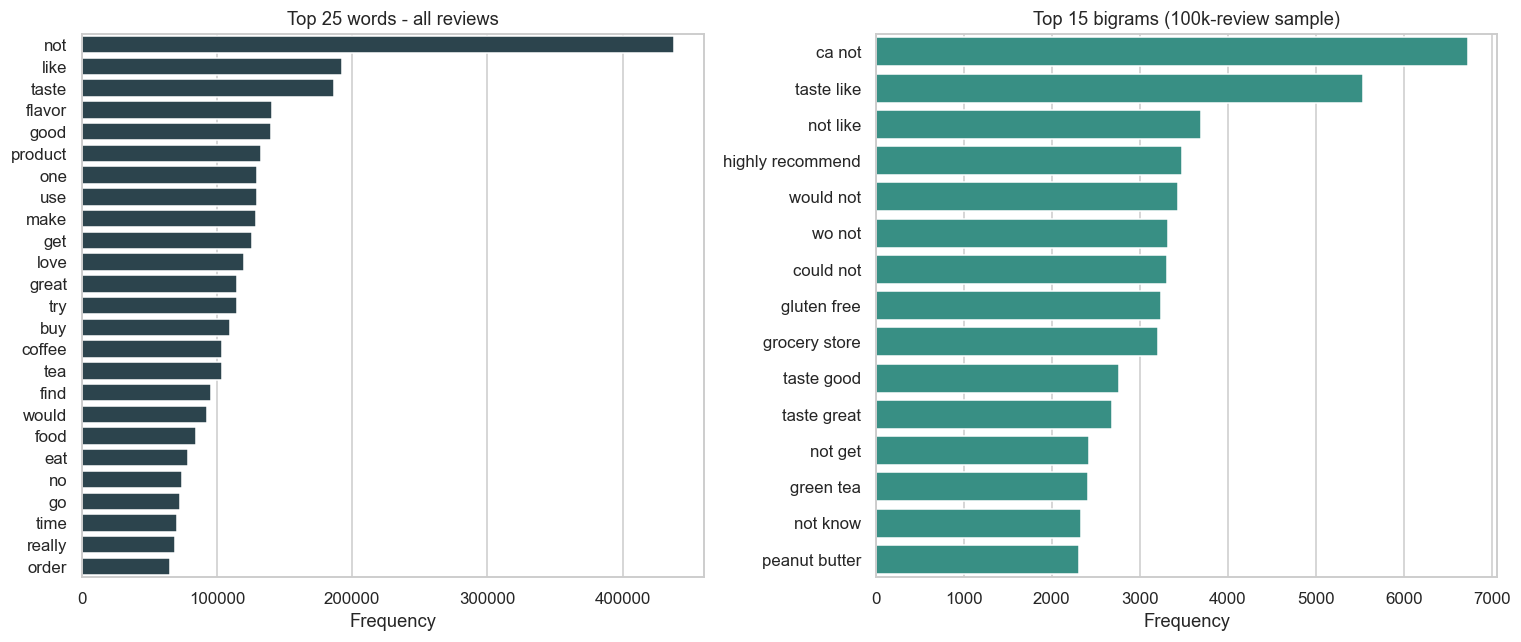

In [36]:
all_counter = pos_counter + neg_counter + word_counter(df.loc[df["Score"] == 3, "CleanText"])

def top_bigrams(series, n=15, sample=100_000, seed=42):
    s = series.sample(min(sample, len(series)), random_state=seed)
    c = Counter()
    for t in s:
        w = t.split()
        c.update(zip(w, w[1:]))
    return c.most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
words, freq = zip(*all_counter.most_common(25))
sns.barplot(x=list(freq), y=list(words), ax=axes[0], color="#264653")
axes[0].set(title="Top 25 words - all reviews", xlabel="Frequency")

bg = top_bigrams(df["CleanText"])
sns.barplot(x=[f for _, f in bg], y=[" ".join(b) for b, _ in bg], ax=axes[1], color="#2a9d8f")
axes[1].set(title="Top 15 bigrams (100k-review sample)", xlabel="Frequency")
plt.tight_layout(); plt.show()

In [37]:
vocab = len(all_counter)
tot = sum(all_counter.values())
hapax = sum(1 for c in all_counter.values() if c == 1)
print("OBSERVATIONS")
print("- Top words:", ", ".join(w for w, _ in all_counter.most_common(10)))
print("- Top bigrams:", ", ".join(" ".join(b) for b, _ in bg[:6]))
print(f"- {tot:,} tokens, vocabulary of {vocab:,} unique words; {hapax/vocab:.1%} of the vocabulary appears only once (typos, rare names).")
print("- Food-domain vocabulary dominates (taste, flavor, coffee, tea, price). Bigrams show strong phrases such as 'highly recommend',")
print("  'taste like' or 'not like' that unigram models miss - n-gram TF-IDF features are worth testing in Sprint 2.")
print("- Dropping very rare words (min_df) will shrink the feature space considerably with little information loss.")

OBSERVATIONS
- Top words: not, like, taste, flavor, good, product, one, use, make, get
- Top bigrams: ca not, taste like, not like, highly recommend, would not, wo not
- 15,913,630 tokens, vocabulary of 89,332 unique words; 48.6% of the vocabulary appears only once (typos, rare names).
- Food-domain vocabulary dominates (taste, flavor, coffee, tea, price). Bigrams show strong phrases such as 'highly recommend',
  'taste like' or 'not like' that unigram models miss - n-gram TF-IDF features are worth testing in Sprint 2.
- Dropping very rare words (min_df) will shrink the feature space considerably with little information loss.


### 5.12 Additional Insights

#### a) Review volume and average rating over time

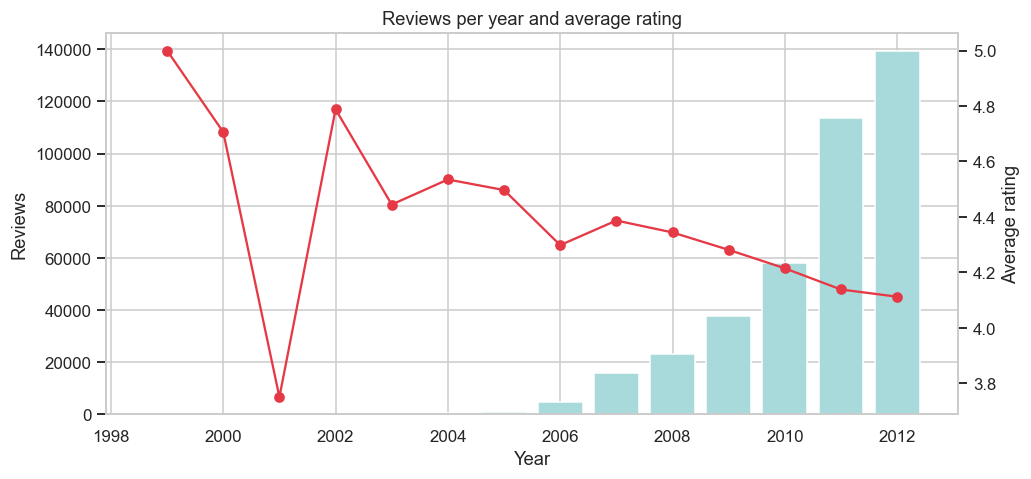

In [38]:
yearly = df.groupby("Year").agg(reviews=("Id", "count"), avg_rating=("Score", "mean"))
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(yearly.index, yearly["reviews"], color="#a8dadc")
ax1.set(xlabel="Year", ylabel="Reviews", title="Reviews per year and average rating")
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["avg_rating"], color="#e63946", marker="o")
ax2.set_ylabel("Average rating"); ax2.grid(False)
plt.show()

In [39]:
print("OBSERVATIONS")
print(f"- Review volume grew from {yearly['reviews'].iloc[0]:,} in {yearly.index[0]} to {yearly['reviews'].max():,} in {yearly['reviews'].idxmax()}.")
print(f"- Average rating ranges from {yearly['avg_rating'].min():.2f} ({yearly['avg_rating'].idxmin()}) "
      f"to {yearly['avg_rating'].max():.2f} ({yearly['avg_rating'].idxmax()}).")
print("- Early years have very few reviews, so their averages are noisy. A time-based train/test split should be considered")
print("  to check whether the model generalises to newer reviews.")

OBSERVATIONS
- Review volume grew from 4 in 1999 to 139,178 in 2012.
- Average rating ranges from 3.75 (2001) to 5.00 (1999).
- Early years have very few reviews, so their averages are noisy. A time-based train/test split should be considered
  to check whether the model generalises to newer reviews.


#### b) Sentiment mix by year

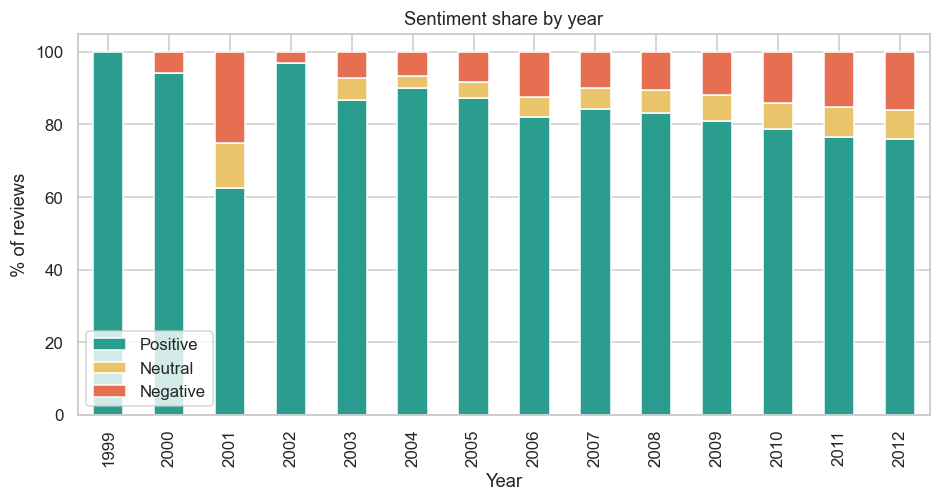

In [40]:
mix = pd.crosstab(df["Year"], df["Sentiment"], normalize="index")[["Positive", "Neutral", "Negative"]] * 100
mix.plot(kind="bar", stacked=True, figsize=(10, 4.5), color=["#2a9d8f", "#e9c46a", "#e76f51"])
plt.title("Sentiment share by year"); plt.ylabel("% of reviews"); plt.xlabel("Year"); plt.legend(loc="lower left")
plt.show()

In [41]:
print("OBSERVATIONS")
print(f"- Positive share ranges from {mix['Positive'].min():.1f}% ({mix['Positive'].idxmin()}) to {mix['Positive'].max():.1f}% ({mix['Positive'].idxmax()}).")
print(f"- Negative share ranges from {mix['Negative'].min():.1f}% to {mix['Negative'].max():.1f}%.")
print("- The class balance is broadly stable over time, so a random split is unlikely to introduce a large distribution shift.")

OBSERVATIONS
- Positive share ranges from 62.5% (2001) to 100.0% (1999).
- Negative share ranges from 0.0% to 25.0%.
- The class balance is broadly stable over time, so a random split is unlikely to introduce a large distribution shift.


#### c) Cleaned review length by sentiment and correlation of numeric features

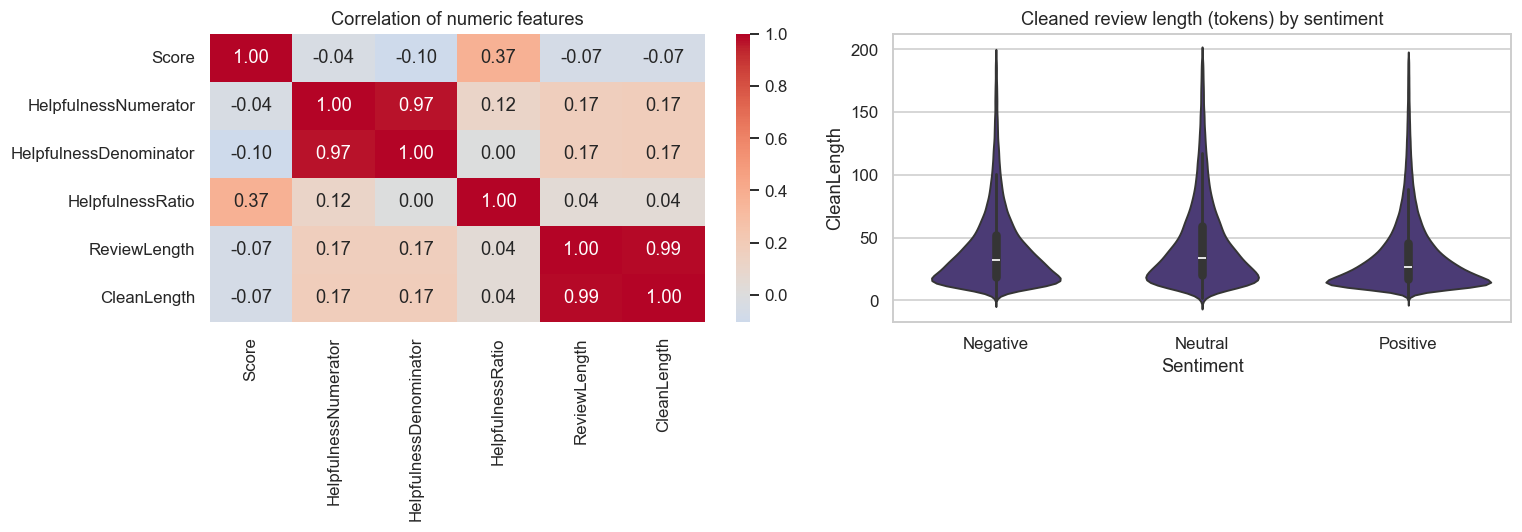

In [42]:
num_cols = ["Score", "HelpfulnessNumerator", "HelpfulnessDenominator", "HelpfulnessRatio", "ReviewLength", "CleanLength"]
corr = df[num_cols].corr()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation of numeric features")
sns.violinplot(data=df[df["CleanLength"] <= df["CleanLength"].quantile(.99)],
               x="Sentiment", y="CleanLength", order=["Negative", "Neutral", "Positive"], ax=axes[1])
axes[1].set(title="Cleaned review length (tokens) by sentiment")
plt.tight_layout(); plt.show()

In [43]:
print("OBSERVATIONS")
print(f"- Correlation Score vs ReviewLength      : {corr.loc['Score','ReviewLength']:+.2f}")
print(f"- Correlation Score vs HelpfulnessRatio  : {corr.loc['Score','HelpfulnessRatio']:+.2f}")
print(f"- Correlation Score vs HelpfulnessDenom. : {corr.loc['Score','HelpfulnessDenominator']:+.2f}")
print("- All correlations with Score are weak, which means meta-features alone cannot predict sentiment;")
print("  the review text itself must carry the signal (TF-IDF / embeddings in Sprint 2).")
print(f"- ReviewLength and CleanLength are almost perfectly correlated ({corr.loc['ReviewLength','CleanLength']:.2f}), so only one is needed as a feature.")

OBSERVATIONS
- Correlation Score vs ReviewLength      : -0.07
- Correlation Score vs HelpfulnessRatio  : +0.37
- Correlation Score vs HelpfulnessDenom. : -0.10
- All correlations with Score are weak, which means meta-features alone cannot predict sentiment;
  the review text itself must carry the signal (TF-IDF / embeddings in Sprint 2).
- ReviewLength and CleanLength are almost perfectly correlated (0.99), so only one is needed as a feature.


## 6. Save the Cleaned Dataset

In [46]:
final_cols = ["Id", "ProductId", "UserId", "ProfileName",
              "HelpfulnessNumerator", "HelpfulnessDenominator", "HelpfulnessRatio",
              "Score", "Sentiment", "ReviewDate", "Year", "Month", "DayOfWeek",
              "ReviewSummary", "ReviewText", "CleanSummary", "CleanText",
              "ReviewLength", "CleanLength"]
df[final_cols].to_csv(OUTPUT_PATH, index=False)
print(f"Saved {len(df):,} rows x {len(final_cols)} columns -> {OUTPUT_PATH}")

Saved 393,883 rows x 19 columns -> cleaned_reviews.csv


In [47]:
raw_rows = 568_454
print("DATA CLEANING SUMMARY")
print(f"- Starting rows (per project brief)   : {raw_rows:,}")
print(f"- Final rows after cleaning           : {len(df):,}")
print(f"- Users / products remaining          : {df['UserId'].nunique():,} / {df['ProductId'].nunique():,}")
print(f"- Sentiment split                     : {df['Sentiment'].value_counts(normalize=True).round(3).to_dict()}")

DATA CLEANING SUMMARY
- Starting rows (per project brief)   : 568,454
- Final rows after cleaning           : 393,883
- Users / products remaining          : 256,052 / 67,612
- Sentiment split                     : {'Positive': 0.779, 'Negative': 0.145, 'Neutral': 0.076}


## 7. Key Takeaways for Sprint 2 (Model Building)

1. **Class imbalance** – reviews are heavily positive; use stratified splits, class weights or resampling, and evaluate with
   precision/recall/F1 and ROC-AUC rather than accuracy.
2. **Neutral (3★) class** – ambiguous; consider a binary task (Positive vs Negative) or treat it as a separate third class.
3. **Negations were preserved** during preprocessing so that bag-of-words / TF-IDF models can learn phrases like *"not good"*.
4. **Text carries the signal** – metadata features (length, helpfulness) are only weakly related to rating.
5. **Bigrams** are informative; try TF-IDF with `ngram_range=(1, 2)` and `min_df` filtering.
6. **Duplicates removed** to prevent identical reviews from appearing in both train and test sets.